In [157]:
import pandas as pd
import numpy as np
import torch.nn as nn

In [158]:
df=pd.read_csv("powerplant_data.csv")
              

In [159]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [160]:
#At => temperture
#v => vacuum
#Ap => pressure
#RH=> humidity

#PE => produced energy


In [161]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [162]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [163]:
#TRAIN TEST SPLIT

from sklearn.model_selection import train_test_split

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [164]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [165]:
#convert the data into tensors (pytorch core DS)

In [166]:
import torch
import torch.nn as nn

X_train_tensor =torch.tensor(X_train_scaled,dtype=torch.float32)
y_train_tensor =torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)


X_test_tensor =torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_tensor =torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)




In [167]:
from torch.utils.data import TensorDataset , DataLoader

train_dataset =TensorDataset(X_train_tensor,y_train_tensor) 
test_dataset =TensorDataset(X_test_tensor,y_test_tensor ) 

In [168]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

In [169]:
# define the odelbulid the ANN model

import torch
import torch.nn as nn

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(
          # 1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),

            # output layer
            nn.Linear(6,1)  
    )

    def forward(self,x):
       return self.model(x)

In [176]:
import torch.optim as optim

model=ANN()

#loss ,optimimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [177]:
# Train the ANN
train_losses=[]
val_losses=[]
epochs =100

best_val_loss=float("inf")

for epoch in range(epochs):
   model.train()
   running_loss=0.0 #total training loss for one epoch
    
    
   for xb , yb in train_loader:
       #xb = fetures of 1 batch 
       #yb = labels of 1 batch
       optimizer.zero_grad()
       output= model(xb)#forward prop...predicted the output for this batch
       loss =crietrion(output,yb)
       loss.backward() # back prop...compute graident
       optimizer.step() #params update

       running_loss+= loss.item() #loss is a tensor ==> py float

   epoch_train_loss =running_loss / len(train_loader)
   train_losses.append(epoch_train_loss)


   #validation
   model.eval()
   running_val_loss=0.0


   with torch.no_grad():#neural network is already train so we dont require the grident update
                       #no gradient compute
     for xb , yb in test_loader:
       #xb = fetures of 1 batch 
       #yb = labels of 1 batch
       
        outputs= model(xb)#forward prop...predicted the output for this batch
        loss =crietrion(outputs,yb)
        running_val_loss=+loss 
         
   epoch_val_loss =running_val_loss / len(test_loader)
   val_losses.append( epoch_val_loss )

   print(f"epoch {epoch+1}/{epochs} ===> training loss= {epoch_train_loss} & val loss = {epoch_val_loss}")

   if epoch_val_loss < best_val_loss:
      best_val_loss=epoch_val_loss
      torch.save(model.state_dict(),"best_model.pt")

epoch 1/100 ===> training loss= 205761.06126302082 & val loss = 3380.90966796875
epoch 2/100 ===> training loss= 195556.66985677084 & val loss = 3024.78564453125
epoch 3/100 ===> training loss= 157433.8116861979 & val loss = 2193.895751953125
epoch 4/100 ===> training loss= 105334.99300130208 & val loss = 1378.942138671875
epoch 5/100 ===> training loss= 70001.9484375 & val loss = 907.9910278320312
epoch 6/100 ===> training loss= 48689.92759602865 & val loss = 585.2409057617188
epoch 7/100 ===> training loss= 31368.544962565105 & val loss = 330.46368408203125
epoch 8/100 ===> training loss= 17544.302461751304 & val loss = 166.88047790527344
epoch 9/100 ===> training loss= 8943.614459228516 & val loss = 91.81591796875
epoch 10/100 ===> training loss= 5012.699370320638 & val loss = 68.38455200195312
epoch 11/100 ===> training loss= 3518.544817606608 & val loss = 52.97050094604492
epoch 12/100 ===> training loss= 2570.1408297220864 & val loss = 39.01160430908203
epoch 13/100 ===> training

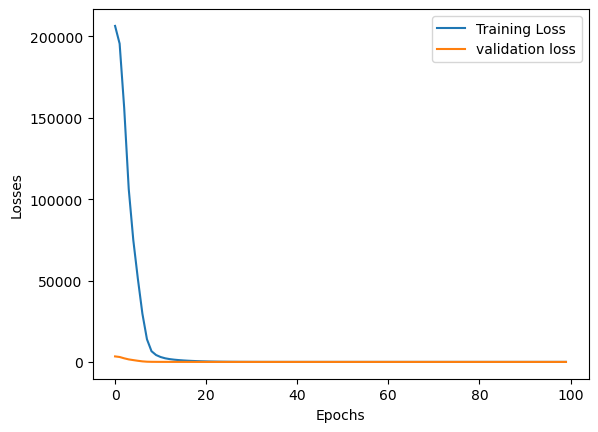

In [172]:
import matplotlib.pyplot as plt

loss_df= pd.DataFrame({
    "training loss":train_losses,
    "validation loss":val_losses
})
plt.plot(loss_df["training loss"],label="Training Loss")
plt.plot(loss_df["validation loss"],label="validation loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [173]:
#loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [179]:
#evalution model

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss =crietrion(train_preds,y_train_tensor)
    test_mse_loss =crietrion(test_preds,y_test_tensor)

print(f"Training MSE : ",train_mse_loss.item())
print(f"Testing MSE : ",test_mse_loss.item())

Training MSE :  19.041614532470703
Testing MSE :  18.048320770263672


In [180]:
from sklearn.metrics import r2_score
print("r^2 score= ",r2_score(y_test,test_preds))

r^2 score=  0.936925780175333


In [181]:
predicated_df = pd.DataFrame(test_preds.numpy(),columns=["Predicated Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicated_df,actual_df],axis=1)

,Predicated Values,Actual Values
0,437.645721,433.27
1,437.946716,438.16
2,460.671661,458.42
3,475.955841,480.82
4,438.504883,441.41
...,...,...
1909,450.629608,456.70
1910,434.084106,438.04
1911,466.648651,467.80
1912,433.449249,437.14
